# 1.0 — Setup & Imports

Mounts Google Drive (when running in Colab), imports all required libraries, and fixes global random seeds for reproducibility.

In [1]:
from scipy.io import loadmat
# ── Standard library ──────────────────────────────────────────────────────────
import os
import sys
import io
import gc
import json
import time
import random
import warnings
from pathlib import Path

# ── Google Colab (optional) ───────────────────────────────────────────────────
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    try:
        from google.colab import drive
    except Exception:
        pass
    IN_COLAB = False

# ── Third-party ───────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, cohen_kappa_score, f1_score,
    ConfusionMatrixDisplay,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ── Global settings ───────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('Python    :', sys.version.split()[0])
print('TensorFlow:', tf.__version__)


Python    : 3.10.13
TensorFlow: 2.16.1


# 2.0 — Configuration

All tunable hyper-parameters, file paths, and architecture constants live here.
Change values in this cell only — nothing else in the notebook should need editing for a standard run.

In [2]:
# ── Environment & Paths ─────────────────────────────────────────────────────────
import glob

IN_KAGGLE = Path('/kaggle').exists()
IN_COLAB  = 'google.colab' in sys.modules

if IN_KAGGLE:
    PROJECT_ROOT = Path('/kaggle/working/Classification')
    DATA_DIR     = Path('/kaggle/input')
    MODEL_DIR    = Path('/kaggle/input')
    DAPM_DIR     = PROJECT_ROOT / 'dapm' / 'dapm_full_artifacts'
elif IN_COLAB:
    PROJECT_ROOT = Path('/kaggle/working/Classification') if IN_KAGGLE else Path('.')
    DATA_DIR     = PROJECT_ROOT / 'data'
    MODEL_DIR    = PROJECT_ROOT / 'baseline' / 'models'
    DAPM_DIR     = PROJECT_ROOT / 'dapm' / 'dapm_full_artifacts'
else:
    PROJECT_ROOT = Path('.')
    DATA_DIR     = Path('./data')
    MODEL_DIR    = Path('./models')
    DAPM_DIR     = Path('./dapm_full_artifacts')

DAPM_DIR.mkdir(parents=True, exist_ok=True)

# Point DATA_DIR to /kaggle/input/dias-dataset-k01 with dynamic glob fallback
mat_candidates = list(Path("/kaggle/input").glob("**/k001.mat")) or list(Path("/kaggle/input").glob("**/DIAS.mat"))
if mat_candidates:
    DATA_DIR = mat_candidates[0].parent
elif Path("data").exists():
    DATA_DIR = Path("data")
else:
    DATA_DIR = Path("/kaggle/input/dias-dataset-k01")

DATA_FILE  = DATA_DIR / "k001.mat" if (DATA_DIR / "k001.mat").exists() else (DATA_DIR / "DIAS.mat" if (DATA_DIR / "DIAS.mat").exists() else DATA_DIR / "k001.mat")
LABEL_FILE = DATA_DIR / "k002.mat" if (DATA_DIR / "k002.mat").exists() else (DATA_DIR / "DIAS_ref.mat" if (DATA_DIR / "DIAS_ref.mat").exists() else DATA_DIR / "k002.mat")


def resolve_model_file(model_dir: Path, obfuscated_name: str, original_name: str) -> Path:
    candidates = [
        model_dir / original_name,
        model_dir / obfuscated_name,
        Path(f"/kaggle/input/{original_name}"),
        Path(f"/kaggle/input/{obfuscated_name}"),
    ]
    for c in candidates:
        if c.exists():
            return c
    found = glob.glob(f"/kaggle/input/**/{original_name}", recursive=True)
    if found:
        return Path(found[0])
    found_obf = glob.glob(f"/kaggle/input/**/{obfuscated_name}", recursive=True)
    if found_obf:
        return Path(found_obf[0])
    local_found = glob.glob(f"**/{original_name}", recursive=True)
    if local_found:
        return Path(local_found[0])
    return candidates[0]

MODEL_FILES = {
    'AlexNet_CNN': resolve_model_file(MODEL_DIR, 'k003.keras', 'AlexNet_CNN_best.keras'),
    'GFNet'      : resolve_model_file(MODEL_DIR, 'k004.keras', 'GFNet_best.keras'),
    'ViT_UNet'   : resolve_model_file(MODEL_DIR, 'k005.keras', 'ViT_UNet_best.keras'),
}
MODEL_KEYS = ['AlexNet_CNN', 'GFNet', 'ViT_UNet']

# ── Image / patch dimensions ───────────────────────────────────────────────────
# H, W, B are inferred automatically from the .mat cube shape
H, W, B     = None, None, None
PERCENTILE_CLIP = (2.0, 98.0)   # height, width, spectral bands
PATCH_SIZE = 9

# ── Data-split fractions ───────────────────────────────────────────────────────
TRAIN_PERCENT          = 0.75
VAL_SPLIT_FROM_TRAIN   = 0.20
MAX_TARGET_UNLABELED   = 20000
TARGET_VAL_FRACTION    = 0.10

# ── DAPM architecture dims ─────────────────────────────────────────────────────
LATENT_DIM           = 64
DECODER_HIDDEN_DIM   = 256
DISCRIM_HIDDEN_DIM   = 128
CLASSIFIER_HIDDEN_DIM = 128
DIFFUSION_HIDDEN_DIM = 256
T_EMBED_DIM          = 32

# ── Training hyper-parameters ─────────────────────────────────────────────────
STAGE1_EPOCHS = 20
STAGE2_EPOCHS = 20
BATCH_SIZE    = 128
STAGE1_LR     = 1e-3
STAGE2_LR     = 1e-3

FREEZE_BACKBONE = True

# ── Loss weights ──────────────────────────────────────────────────────────────
LAMBDA_SRC_RECON = 1.0
LAMBDA_TGT_RECON = 1.0
LAMBDA_KL        = 0.01
LAMBDA_CE        = 1.0
LAMBDA_DOMAIN    = 0.2
LAMBDA_TGT_DIFF  = 0.5

# ── Diffusion schedule ────────────────────────────────────────────────────────
DIFFUSION_T = 100
BETA_START  = 1e-4
BETA_END    = 2e-2

print('Project root:', PROJECT_ROOT)
print('Data file   :', DATA_FILE)
print('Label file  :', LABEL_FILE)
print('DAPM dir    :', DAPM_DIR)
for k, v in MODEL_FILES.items():
    print(f'Model {k}: {v}')

# ── Visualisation palette ─────────────────────────────────────────────
import colorsys
from matplotlib.colors import ListedColormap

CLASS_COLOR_BASE = [
    '#0000FF', '#00FF00', '#FF0000', '#00FFFF', '#FF00FF',
    '#FFFF00', '#A52A2A', '#FFA500', '#7FFF00', '#8A2BE2',
]
BACKGROUND_COLOR = '#000000'
UNCERTAIN_COLOR  = '#808080'

def _generate_extra_shades(n_extra, hue_offset=0.05, sat=0.85, val=0.95):
    """Bold, highly-saturated extra hues in the same style as CLASS_COLOR_BASE."""
    shades = []
    for i in range(n_extra):
        hue = (hue_offset + i / max(n_extra, 1)) % 1.0
        r, g, b = colorsys.hsv_to_rgb(hue, sat, val)
        shades.append('#%02x%02x%02x' % (int(r * 255), int(g * 255), int(b * 255)))
    return shades

def get_class_colors(n):
    """Return n visually distinct hex colours; extends past the base 10 with
    additional bold shades generated in the same saturated style."""
    if n <= len(CLASS_COLOR_BASE):
        return CLASS_COLOR_BASE[:n]
    return CLASS_COLOR_BASE + _generate_extra_shades(n - len(CLASS_COLOR_BASE))

def resolve_uncertain_color(class_colors, preferred=UNCERTAIN_COLOR, min_dist=60):
    """Return `preferred` unless it visually clashes with any class colour, in
    which case fall back to a distinct dark slate so 'Uncertain' never collides."""
    def _hex_to_rgb(h):
        h = h.lstrip('#')
        return tuple(int(h[i:i+2], 16) for i in (0, 2, 4))
    pr, pg, pb = _hex_to_rgb(preferred)
    for c in class_colors:
        cr, cg, cb = _hex_to_rgb(c)
        dist = ((pr - cr) ** 2 + (pg - cg) ** 2 + (pb - cb) ** 2) ** 0.5
        if dist < min_dist:
            return '#2F2F2F'
    return preferred

def get_display_cmap(num_classes):
    """Build a ListedColormap: index 0 = background black, 1..K = class colours."""
    return ListedColormap([BACKGROUND_COLOR] + get_class_colors(num_classes))

def get_scene_rgb(x_img, bands):
    """Select three bands as an approximate RGB composite; clip to [0, 1]."""
    if bands >= 6:
        rgb_idx = [bands // 2 - 1, bands // 2, bands // 2 + 1]
    elif bands >= 3:
        rgb_idx = [0, 1, 2]
    else:
        raise ValueError(f"Need at least 3 bands to form RGB, got {bands}.")
    return np.clip(x_img[:, :, rgb_idx], 0.0, 1.0)


Project root: /kaggle/working/Classification
Data file   : /kaggle/input/dias-dataset-k01/k001.mat
Label file  : /kaggle/input/dias-dataset-k01/k002.mat
DAPM dir    : /kaggle/working/Classification/dapm/dapm_full_artifacts
Model AlexNet_CNN: /kaggle/input/dias-baseline-k03/k003.keras
Model GFNet: /kaggle/input/dias-baseline-k03/k004.keras
Model ViT_UNet: /kaggle/input/dias-baseline-k03/k005.keras


# 3.0 — Data Pipeline

## 3.1 — Loading & Normalisation

Reads the multispectral CSV files and applies per-band min-max normalisation.

In [3]:
def load_scene_from_mat(data_path, label_path, data_key=None, label_key=None):
    """Load a hyperspectral/multispectral scene + reference labels from .mat files.

    Works for any band count / scene size (previously hard-coded to 6-band CSV
    scenes). If data_key / label_key are not given, the first non-metadata
    variable in each .mat file is used automatically — this matches files
    such as DIAS.mat / DIAS_ref.mat where the array is stored under a single
    named variable. Each spectral band is robustly stretched to [0, 1] using
    a percentile clip (see PERCENTILE_CLIP) rather than literal min/max.
    """
    data_mat  = loadmat(data_path)
    label_mat = loadmat(label_path)

    def _first_array(mat_dict, key):
        if key is not None:
            return mat_dict[key]
        candidates = [v for k, v in mat_dict.items() if not k.startswith("__")]
        if not candidates:
            raise ValueError(f"No data arrays found in {mat_dict.keys()}")
        return candidates[0]

    x = _first_array(data_mat, data_key).astype(np.float32)
    y = _first_array(label_mat, label_key).astype(np.int32)

    if x.ndim != 3:
        raise ValueError(f"Expected a (H, W, Bands) cube, got shape {x.shape}")
    if y.shape != x.shape[:2]:
        raise ValueError(f"Label shape {y.shape} does not match image shape {x.shape[:2]}")

    height, width, bands = x.shape

    # Robust per-band stretch: clip to the [lower_pct, upper_pct] percentile
    # range before min-max scaling, instead of literal min/max. A handful of
    # saturated/no-data pixels (e.g. sensor clipping at the int8 range limits
    # -128/127) would otherwise dominate the stretch and crush the dynamic
    # range of the rest of the scene.
    x_norm = np.empty_like(x, dtype=np.float32)
    for b in range(bands):
        band = x[:, :, b]
        lo   = np.percentile(band, PERCENTILE_CLIP[0])
        hi   = np.percentile(band, PERCENTILE_CLIP[1])
        denom = max(hi - lo, 1e-8)
        band_clipped = np.clip(band, lo, hi)
        x_norm[:, :, b] = (band_clipped - lo) / denom

    return x_norm, y, height, width, bands


def extract_labeled_patches(x, y, patch_size=9):
    """Extract (patch_size × patch_size) spatial patches around every labelled pixel."""
    pad   = patch_size // 2
    x_pad = np.pad(x, ((pad, pad), (pad, pad), (0, 0)), mode="edge")

    coords  = np.argwhere(y > 0)
    patches = np.empty((coords.shape[0], patch_size, patch_size, x.shape[-1]), dtype=np.float32)
    labels  = np.empty((coords.shape[0],), dtype=np.int32)

    for i, (r, c) in enumerate(coords):
        patches[i] = x_pad[r:r + patch_size, c:c + patch_size, :]
        labels[i]  = int(y[r, c]) - 1  # convert class IDs to 0..C-1

    return patches, labels, coords



## 3.2 — Patch Extraction

Extracts fixed-size spatial patches centred on given pixel coordinates.
Separate helpers handle labeled (source) and unlabeled (target) pixels.

In [4]:
def extract_patches_from_coords(x_img, coords, patch_size=9):
    """Extract (patch_size x patch_size x bands) patches at each (row, col) coordinate."""
    pad   = patch_size // 2
    x_pad = np.pad(x_img, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    out   = np.empty((coords.shape[0], patch_size, patch_size, x_img.shape[-1]), dtype=np.float32)
    for i, (r, c) in enumerate(coords):
        out[i] = x_pad[r:r + patch_size, c:c + patch_size, :]
    return out


def extract_labeled_patches_with_coords(x_img, y_img, patch_size=9):
    """Return patches, 0-based labels, and coordinates for all labeled (y > 0) pixels."""
    coords   = np.argwhere(y_img > 0)
    x_patches = extract_patches_from_coords(x_img, coords, patch_size=patch_size)
    y_labels  = np.array([int(y_img[r, c]) - 1 for r, c in coords], dtype=np.int32)
    return x_patches, y_labels, coords


def extract_unlabeled_patches_with_coords(x_img, y_img, patch_size=9, max_samples=None, seed=42):
    """Return patches and coordinates for unlabeled (y == 0) pixels, with optional subsampling."""
    coords = np.argwhere(y_img == 0)
    if max_samples is not None and coords.shape[0] > max_samples:
        rng    = np.random.default_rng(seed)
        keep   = rng.choice(coords.shape[0], size=max_samples, replace=False)
        coords = coords[keep]
    x_patches = extract_patches_from_coords(x_img, coords, patch_size=patch_size)
    return x_patches, coords


## 3.3 — Build Train / Val / Test Splits

Loads the image, extracts source (labeled) and target (unlabeled) patches,
and performs stratified splits.

In [5]:
x_img, y_img, H, W, B = load_scene_from_mat(DATA_FILE, LABEL_FILE)
X_all, y_all, coords_all = extract_labeled_patches_with_coords(x_img, y_img, PATCH_SIZE)
num_classes = int(np.unique(y_all).size)

# Source domain: stratified 75 / 25 train+val / test split
x_train_full, x_test, y_train_full, y_test, coords_train_full, coords_test = train_test_split(
    X_all, y_all, coords_all,
    train_size=TRAIN_PERCENT, random_state=SEED, stratify=y_all,
)
# Further split train → train / val (20 % of train)
x_train, x_val, y_train, y_val, coords_train, coords_val = train_test_split(
    x_train_full, y_train_full, coords_train_full,
    test_size=VAL_SPLIT_FROM_TRAIN, random_state=SEED, stratify=y_train_full,
)

# Target domain: unlabeled pixels, randomly sub-sampled
X_target_all, coords_target_all = extract_unlabeled_patches_with_coords(
    x_img, y_img, patch_size=PATCH_SIZE,
    max_samples=MAX_TARGET_UNLABELED, seed=SEED,
)
x_target_train, x_target_val, coords_target_train, coords_target_val = train_test_split(
    X_target_all, coords_target_all,
    test_size=TARGET_VAL_FRACTION, random_state=SEED, shuffle=True,
)

print('x_img           :', x_img.shape, '  y_img:', y_img.shape)
print('Source train/val/test:', x_train.shape, x_val.shape, x_test.shape)
print('Target train/val    :', x_target_train.shape, x_target_val.shape)
print('num_classes         :', num_classes)


x_img           : (512, 512, 65)   y_img: (512, 512)
Source train/val/test: (32335, 9, 9, 65) (8084, 9, 9, 65) (13474, 9, 9, 65)
Target train/val    : (18000, 9, 9, 65) (2000, 9, 9, 65)
num_classes         : 8


# 4.0 — Custom Keras Layers & Backbone Loaders

## 4.1 — Custom Layers for Base Models

Registers the serialisable custom layers required to reload the pre-trained `.keras` files.
These layers are **not** trained here — they are part of the frozen backbones.

In [6]:
@tf.keras.utils.register_keras_serializable()
class PatchExtractor(layers.Layer):
    """Extract non-overlapping image patches via tf.image.extract_patches."""

    def __init__(self, patch_size=3, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        patches   = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding='VALID',
        )
        batch     = tf.shape(images)[0]
        num_patches = tf.shape(patches)[1] * tf.shape(patches)[2]
        patch_dim = tf.shape(patches)[-1]
        return tf.reshape(patches, [batch, num_patches, patch_dim])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'patch_size': self.patch_size})
        return cfg


@tf.keras.utils.register_keras_serializable()
class PatchPositionEncoder(layers.Layer):
    """Project patches and add learned positional embeddings."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches    = num_patches
        self.projection_dim = projection_dim
        self.projection          = layers.Dense(projection_dim)
        self.position_embedding  = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)

    def call(self, patches):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patches) + self.position_embedding(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'num_patches': self.num_patches, 'projection_dim': self.projection_dim})
        return cfg


@tf.keras.utils.register_keras_serializable()
class GlobalFilterLayer(layers.Layer):
    """GFNet global filter: learnable 2-D frequency-domain weights."""

    def __init__(self, token_side, **kwargs):
        super().__init__(**kwargs)
        self.token_side = token_side

    def build(self, input_shape):
        channels = int(input_shape[-1])
        self.w_real = self.add_weight(
            name='w_real', shape=(self.token_side, self.token_side, channels),
            initializer='glorot_uniform', trainable=True,
        )
        self.w_imag = self.add_weight(
            name='w_imag', shape=(self.token_side, self.token_side, channels),
            initializer='zeros', trainable=True,
        )
        super().build(input_shape)

    def call(self, x):
        batch    = tf.shape(x)[0]
        channels = tf.shape(x)[-1]
        x_2d     = tf.reshape(x, [batch, self.token_side, self.token_side, channels])
        x_fft    = tf.signal.fft2d(tf.cast(x_2d, tf.complex64))
        w_complex  = tf.complex(self.w_real, self.w_imag)
        x_filtered = x_fft * w_complex
        x_spatial  = tf.math.real(tf.signal.ifft2d(x_filtered))
        return tf.reshape(x_spatial, [batch, self.token_side * self.token_side, channels])

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'token_side': self.token_side})
        return cfg


@tf.keras.utils.register_keras_serializable()
class PatchEncoderWithCLS(layers.Layer):
    """ViT-style patch encoder with a prepended learnable [CLS] token."""

    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches    = num_patches
        self.projection_dim = projection_dim
        self.projection         = layers.Dense(projection_dim)
        self.position_embedding = layers.Embedding(input_dim=num_patches + 1, output_dim=projection_dim)

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            name='cls_token', shape=(1, 1, self.projection_dim),
            initializer='zeros', trainable=True,
        )
        super().build(input_shape)

    def call(self, patches):
        batch      = tf.shape(patches)[0]
        patch_proj = self.projection(patches)
        cls_tokens = tf.repeat(self.cls_token, repeats=batch, axis=0)
        x          = tf.concat([cls_tokens, patch_proj], axis=1)
        positions  = tf.range(start=0, limit=self.num_patches + 1, delta=1)
        return x + self.position_embedding(positions)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'num_patches': self.num_patches, 'projection_dim': self.projection_dim})
        return cfg


CUSTOM_OBJECTS = {
    'PatchExtractor'      : PatchExtractor,
    'PatchPositionEncoder': PatchPositionEncoder,
    'GlobalFilterLayer'   : GlobalFilterLayer,
    'PatchEncoderWithCLS' : PatchEncoderWithCLS,
}

# ── Robust Backbone Loader across Python versions (bypasses Lambda bytecode deserialization) ──
import zipfile

def transformer_block(x, num_heads, projection_dim, mlp_dim, dropout_rate, name_prefix):
    """Standard pre-LN transformer block with multi-head attention and a GELU MLP."""
    y = layers.LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln1")(x)
    y = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=projection_dim,
        dropout=dropout_rate, name=f"{name_prefix}_mha",
    )(y, y)
    x = layers.Add(name=f"{name_prefix}_add1")([y, x])

    y = layers.LayerNormalization(epsilon=1e-6, name=f"{name_prefix}_ln2")(x)
    y = layers.Dense(mlp_dim, activation=tf.keras.activations.gelu, name=f"{name_prefix}_mlp1")(y)
    y = layers.Dropout(dropout_rate, name=f"{name_prefix}_drop1")(y)
    y = layers.Dense(projection_dim, activation=tf.keras.activations.gelu, name=f"{name_prefix}_mlp2")(y)
    y = layers.Dropout(dropout_rate, name=f"{name_prefix}_drop2")(y)
    return layers.Add(name=f"{name_prefix}_add2")([y, x])


def build_vit_unet_singlehead(
    input_shape=(9, 9, 65), num_classes=8, inner_patch=3,
    projection_dim=256, num_heads=4, transformer_layers=12,
    mlp_multiplier=2, dropout_rate=0.25, head_units=(512, 256, 128, 64),
):
    """Build a ViT single-head classifier matching dias-baseline-k03."""
    num_patches = (input_shape[0] // inner_patch) * (input_shape[1] // inner_patch)

    inputs = keras.Input(shape=input_shape)
    x      = PatchExtractor(inner_patch, name="vit_patch_extractor")(inputs)
    x      = PatchEncoderWithCLS(num_patches, projection_dim, name="vit_patch_encoder")(x)

    block_list = []
    for i in range(transformer_layers):
        x = transformer_block(
            x, num_heads=num_heads, projection_dim=projection_dim,
            mlp_dim=projection_dim * mlp_multiplier,
            dropout_rate=0.1, name_prefix=f"vit_block_{i+1}",
        )
        if i <= transformer_layers // 2:
            block_list.append(x)
        else:
            x = layers.Add(name=f"vit_skip_add_{i+1}")([x, block_list[transformer_layers - i - 1]])

    x         = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_1")(x)
    x         = layers.LayerNormalization(epsilon=1e-6, name="vit_cls_norm")(x)
    cls_token = layers.Lambda(lambda t: t[:, 0, :], name="vit_cls_token")(x)

    y = layers.Dense(head_units[0], activation=tf.keras.activations.gelu, name="vit_head_1")(cls_token)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_3")(y)
    y = layers.Dense(head_units[1], activation=tf.keras.activations.gelu, name="vit_head_2")(y)
    y = layers.Dense(head_units[2], activation=tf.keras.activations.gelu, name="vit_head_3")(y)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_5")(y)
    y = layers.Dense(head_units[3], activation=tf.keras.activations.gelu, name="vit_head_4")(y)
    y = layers.Dropout(dropout_rate, name="TRAIN_DROPOUT_6")(y)

    outputs = layers.Dense(num_classes, activation="softmax", name="vit_logits")(y)
    return keras.Model(inputs, outputs, name="ViT_UNet_SingleHead")


def load_backbone_model(path, model_key, custom_objects, input_shape=(9, 9, 65), num_classes=8):
    """Load model safely without Python bytecode deserialization crash."""
    path_obj = Path(path)
    if not path_obj.exists():
        raise FileNotFoundError(f"Missing base model: {path}")

    if model_key == "ViT_UNet":
        model = build_vit_unet_singlehead(input_shape=input_shape, num_classes=num_classes)
        try:
            model.load_weights(str(path_obj))
        except Exception:
            if zipfile.is_zipfile(path_obj):
                with zipfile.ZipFile(path_obj, "r") as z:
                    if "model.weights.h5" in z.namelist():
                        tmp_w = f"/tmp/{model_key}_weights.h5"
                        with open(tmp_w, "wb") as f_out:
                            f_out.write(z.read("model.weights.h5"))
                        model.load_weights(tmp_w)
                    else:
                        raise
            else:
                raise
        return model
    else:
        return keras.models.load_model(str(path_obj), custom_objects=custom_objects, compile=False, safe_mode=False)


## 4.2 — Load Backbones & Build Feature Extractors

Loads each pre-trained `.keras` model, slices off the final classification head,
and optionally freezes all backbone weights.

In [7]:
def get_feature_extractor(base_model, freeze_backbone=True):
    """Return a sub-model that outputs the penultimate (pre-logit) layer activations."""
    penultimate = base_model.layers[-2].output
    feat_model  = keras.Model(
        base_model.input, penultimate,
        name=f'{base_model.name}_feature_extractor',
    )
    feat_model.trainable = not freeze_backbone
    return feat_model


base_models        = {}
feature_extractors = {}
feature_dims       = {}

for model_key in MODEL_KEYS:
    path = MODEL_FILES[model_key]
    model = load_backbone_model(
        path, model_key, CUSTOM_OBJECTS,
        input_shape=(PATCH_SIZE, PATCH_SIZE, B),
        num_classes=num_classes,
    )
    extractor = get_feature_extractor(model, freeze_backbone=FREEZE_BACKBONE)
    feature_dim = int(extractor.output_shape[-1])

    base_models[model_key]        = model
    feature_extractors[model_key] = extractor
    feature_dims[model_key]       = feature_dim

    print(model_key, 'loaded from', path)
    print('  feature_dim =', feature_dim)


AlexNet_CNN loaded from /kaggle/input/dias-baseline-k03/k003.keras
  feature_dim = 32
GFNet loaded from /kaggle/input/dias-baseline-k03/k004.keras
  feature_dim = 512
ViT_UNet loaded from /kaggle/input/dias-baseline-k03/k005.keras
  feature_dim = 64


# 5.0 — DAPM Module Definitions

## 5.1 — Core Keras Layers (Sampling, GRL)

Defines the two custom layers used inside the DAPM heads:
the VAE reparameterisation sampler and the Gradient Reversal Layer (GRL).

In [8]:
@tf.keras.utils.register_keras_serializable()
class Sampling(layers.Layer):
    """VAE reparameterisation trick: z = mu + exp(0.5 * logvar) * eps."""

    def call(self, inputs):
        z_mu, z_logvar = inputs
        eps = tf.random.normal(shape=tf.shape(z_mu))
        return z_mu + tf.exp(0.5 * z_logvar) * eps


@tf.keras.utils.register_keras_serializable()
class GradientReversal(layers.Layer):
    """Flip gradients by -lambda_ during back-propagation (domain adversarial training)."""

    def __init__(self, lambda_=1.0, **kwargs):
        super().__init__(**kwargs)
        self.lambda_ = float(lambda_)

    def call(self, x):
        lambda_ = self.lambda_

        @tf.custom_gradient
        def _flip_gradients(v):
            def grad(dy):
                return -lambda_ * dy
            return v, grad

        return _flip_gradients(x)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({'lambda_': self.lambda_})
        return cfg


## 5.2 — DAPM Network Builders

Factory functions for the five sub-networks: encoder (VAE), source/target decoders,
classifier, domain discriminator, and the conditional diffusion model.

In [9]:
def build_dapm_encoder(feature_dim, latent_dim=64, hidden_dim=256):
    """VAE encoder: feature vector → (z_mu, z_logvar, z_sample)."""
    inp      = keras.Input(shape=(feature_dim,), name='enc_feature_in')
    h        = layers.Dense(hidden_dim, activation='relu', name='enc_h1')(inp)
    h        = layers.Dense(hidden_dim, activation='relu', name='enc_h2')(h)
    z_mu     = layers.Dense(latent_dim, name='z_mu')(h)
    z_logvar = layers.Dense(latent_dim, name='z_logvar')(h)
    z        = Sampling(name='z_sample')([z_mu, z_logvar])
    return keras.Model(inp, [z_mu, z_logvar, z], name='dapm_full_encoder')


def build_dapm_decoder(latent_dim, feature_dim, hidden_dim=256, name='dapm_full_decoder'):
    """Decoder: latent vector → reconstructed feature vector."""
    inp = keras.Input(shape=(latent_dim,), name=f'{name}_z_in')
    h   = layers.Dense(hidden_dim, activation='relu', name=f'{name}_h1')(inp)
    h   = layers.Dense(hidden_dim, activation='relu', name=f'{name}_h2')(h)
    out = layers.Dense(feature_dim, activation='linear', name=f'{name}_out')(h)
    return keras.Model(inp, out, name=name)


def build_dapm_classifier(latent_dim, num_classes, hidden_dim=128):
    """Classifier head: latent vector → class probabilities."""
    inp = keras.Input(shape=(latent_dim,), name='clf_z_in')
    h   = layers.Dense(hidden_dim, activation='relu', name='clf_h1')(inp)
    out = layers.Dense(num_classes, activation='softmax', name='clf_out')(h)
    return keras.Model(inp, out, name='dapm_full_classifier')


def build_dapm_discriminator(latent_dim, hidden_dim=128, grl_lambda=1.0):
    """Domain discriminator with Gradient Reversal Layer: latent → P(target domain)."""
    inp = keras.Input(shape=(latent_dim,), name='disc_z_in')
    x   = GradientReversal(lambda_=grl_lambda, name='disc_grl')(inp)
    x   = layers.Dense(hidden_dim, activation='relu', name='disc_h1')(x)
    x   = layers.Dense(hidden_dim, activation='relu', name='disc_h2')(x)
    out = layers.Dense(1, activation='sigmoid', name='disc_out')(x)
    return keras.Model(inp, out, name='dapm_full_discriminator')


def build_dapm_diffusion(latent_dim, num_classes, T=100, t_embed_dim=32, hidden_dim=256):
    """Conditional diffusion noise predictor: (z, y_t, guidance, t) → eps_pred."""
    z_in   = keras.Input(shape=(latent_dim,),   name='diff_z_in')
    y_t_in = keras.Input(shape=(num_classes,),  name='diff_y_t')
    f_in   = keras.Input(shape=(num_classes,),  name='diff_guidance')
    t_in   = keras.Input(shape=(1,), dtype='int32', name='diff_t')

    t_emb    = layers.Embedding(input_dim=T + 1, output_dim=t_embed_dim, name='diff_t_embed')(t_in)
    t_emb    = layers.Flatten(name='diff_t_flat')(t_emb)
    x        = layers.Concatenate(name='diff_concat')([z_in, y_t_in, f_in, t_emb])
    x        = layers.Dense(hidden_dim, activation='relu', name='diff_h1')(x)
    x        = layers.Dense(hidden_dim, activation='relu', name='diff_h2')(x)
    eps_pred = layers.Dense(num_classes, activation='linear', name='diff_eps_pred')(x)

    return keras.Model([z_in, y_t_in, f_in, t_in], eps_pred, name='dapm_full_diffusion')


# 6.0 — Training Utilities

## 6.1 — Loss Functions

Shared loss helpers used by both training stages.

In [10]:
def kl_loss_from_stats(z_mu, z_logvar):
    """KL divergence from N(0,1): averaged over batch."""
    return -0.5 * tf.reduce_mean(
        tf.reduce_sum(1.0 + z_logvar - tf.square(z_mu) - tf.exp(z_logvar), axis=-1)
    )


def recon_loss(x_true, x_rec):
    """Mean sum-of-squared-errors reconstruction loss."""
    return tf.reduce_mean(tf.reduce_sum(tf.square(x_true - x_rec), axis=-1))


def domain_bce(y_true, y_prob):
    """Binary cross-entropy for domain labels."""
    y_true = tf.cast(y_true, tf.float32)
    return tf.reduce_mean(keras.losses.binary_crossentropy(y_true, y_prob))


## 6.2 — Data Stream & Diffusion Helpers

In [11]:
def build_target_batch_stream(x_target, batch_size, seed=42):
    """Infinite shuffled iterator over target-domain patches."""
    ds = tf.data.Dataset.from_tensor_slices(x_target)
    ds = ds.shuffle(len(x_target), seed=seed, reshuffle_each_iteration=True)
    ds = ds.repeat().batch(batch_size, drop_remainder=True)
    return iter(ds)


def make_beta_schedule(T, beta_start=1e-4, beta_end=2e-2):
    """Linear beta schedule → (betas, alphas, alpha_bars)."""
    betas      = np.linspace(beta_start, beta_end, T, dtype=np.float32)
    alphas     = 1.0 - betas
    alpha_bars = np.cumprod(alphas)
    return betas, alphas, alpha_bars


def sample_timesteps(batch_size, T):
    """Uniformly sample integer timesteps in [1, T]."""
    return np.random.randint(1, T + 1, size=(batch_size, 1), dtype=np.int32)


def q_sample(y0, t_idx, alpha_bars):
    """Forward diffusion: add noise to y0 at timestep t_idx using precomputed alpha_bars."""
    a_bar = tf.gather(alpha_bars, tf.cast(tf.squeeze(t_idx, axis=-1) - 1, tf.int32))
    a_bar = tf.cast(tf.reshape(a_bar, (-1, 1)), tf.float32)
    eps   = tf.random.normal(tf.shape(y0), dtype=tf.float32)
    y_t   = tf.sqrt(a_bar) * y0 + tf.sqrt(1.0 - a_bar) * eps
    return y_t, eps


# 7.0 — DAPM Training Stages

## 7.1 — Stage 1: VAE + Domain Adversarial Training

Trains the encoder, source/target decoders, classifier, and discriminator jointly.
The GRL inside the discriminator aligns source and target latent distributions.

In [12]:
def train_stage1_for_model(model_key, feature_extractor, num_classes):
    """Run Stage-1 DAPM training for one backbone and return trained sub-networks + history."""
    feature_dim   = int(feature_extractor.output_shape[-1])
    encoder       = build_dapm_encoder(feature_dim, latent_dim=LATENT_DIM, hidden_dim=DECODER_HIDDEN_DIM)
    src_decoder   = build_dapm_decoder(LATENT_DIM, feature_dim, hidden_dim=DECODER_HIDDEN_DIM, name='dapm_full_source_decoder')
    tgt_decoder   = build_dapm_decoder(LATENT_DIM, feature_dim, hidden_dim=DECODER_HIDDEN_DIM, name='dapm_full_target_decoder')
    classifier    = build_dapm_classifier(LATENT_DIM, num_classes, hidden_dim=CLASSIFIER_HIDDEN_DIM)
    discriminator = build_dapm_discriminator(LATENT_DIM, hidden_dim=DISCRIM_HIDDEN_DIM, grl_lambda=1.0)

    opt = keras.optimizers.Adam(STAGE1_LR)

    train_ds = (
        tf.data.Dataset.from_tensor_slices((x_train.astype(np.float32), y_train.astype(np.int32)))
        .shuffle(len(x_train), seed=SEED)
        .batch(BATCH_SIZE, drop_remainder=False)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((x_val.astype(np.float32), y_val.astype(np.int32)))
        .batch(BATCH_SIZE)
    )
    tgt_iter = build_target_batch_stream(x_target_train.astype(np.float32), BATCH_SIZE, seed=SEED)

    history    = []
    stage1_vars = (
        encoder.trainable_variables +
        src_decoder.trainable_variables +
        tgt_decoder.trainable_variables +
        classifier.trainable_variables +
        discriminator.trainable_variables
    )

    for epoch in range(STAGE1_EPOCHS):
        meters = {k: [] for k in ['loss', 'src_recon', 'tgt_recon', 'src_kl', 'tgt_kl', 'src_ce', 'domain']}

        for xb_src, yb_src in train_ds:
            xb_tgt = next(tgt_iter)
            with tf.GradientTape() as tape:
                # ── Source branch ──────────────────────────────────────────
                feat_src          = feature_extractor(xb_src, training=not FREEZE_BACKBONE)
                z_mu_src, z_logvar_src, z_src = encoder(feat_src, training=True)
                feat_src_rec      = src_decoder(z_src, training=True)
                y_src_prob        = classifier(z_src, training=True)
                dom_src_prob      = discriminator(z_src, training=True)

                # ── Target branch ──────────────────────────────────────────
                feat_tgt          = feature_extractor(xb_tgt, training=not FREEZE_BACKBONE)
                z_mu_tgt, z_logvar_tgt, z_tgt = encoder(feat_tgt, training=True)
                feat_tgt_rec      = tgt_decoder(z_tgt, training=True)
                dom_tgt_prob      = discriminator(z_tgt, training=True)

                # ── Losses ────────────────────────────────────────────────
                src_recon = recon_loss(feat_src, feat_src_rec)
                tgt_recon = recon_loss(feat_tgt, feat_tgt_rec)
                src_kl    = kl_loss_from_stats(z_mu_src, z_logvar_src)
                tgt_kl    = kl_loss_from_stats(z_mu_tgt, z_logvar_tgt)
                src_ce    = tf.reduce_mean(
                    keras.losses.sparse_categorical_crossentropy(yb_src, y_src_prob)
                )
                dom_loss  = (
                    domain_bce(tf.zeros_like(dom_src_prob), dom_src_prob) +
                    domain_bce(tf.ones_like(dom_tgt_prob),  dom_tgt_prob)
                )
                loss = (
                    LAMBDA_SRC_RECON * src_recon +
                    LAMBDA_TGT_RECON * tgt_recon +
                    LAMBDA_KL        * (src_kl + tgt_kl) +
                    LAMBDA_CE        * src_ce +
                    LAMBDA_DOMAIN    * dom_loss
                )

            grads = tape.gradient(loss, stage1_vars)
            opt.apply_gradients(zip(grads, stage1_vars))

            for k, v in [('loss', loss), ('src_recon', src_recon), ('tgt_recon', tgt_recon),
                         ('src_kl', src_kl), ('tgt_kl', tgt_kl), ('src_ce', src_ce), ('domain', dom_loss)]:
                meters[k].append(float(v))

        # ── Validation ──────────────────────────────────────────────────────
        val_acc_meter, val_ce_meter, val_src_recon_meter = [], [], []
        for xb_val, yb_val in val_ds:
            feat_val              = feature_extractor(xb_val, training=False)
            z_mu_val, z_logvar_val, z_val = encoder(feat_val, training=False)
            feat_val_rec          = src_decoder(z_val, training=False)
            y_val_prob            = classifier(z_val, training=False)
            val_pred              = tf.argmax(y_val_prob, axis=-1, output_type=tf.int32)
            val_acc_meter.append(float(tf.reduce_mean(tf.cast(tf.equal(val_pred, yb_val), tf.float32))))
            val_ce_meter.append(float(tf.reduce_mean(keras.losses.sparse_categorical_crossentropy(yb_val, y_val_prob))))
            val_src_recon_meter.append(float(recon_loss(feat_val, feat_val_rec)))

        tgt_val_ds = (
            tf.data.Dataset.from_tensor_slices(x_target_val.astype(np.float32))
            .batch(BATCH_SIZE)
        )
        tgt_recon_val_meter = []
        for xb_tval in tgt_val_ds:
            feat_tval                    = feature_extractor(xb_tval, training=False)
            z_mu_tval, z_logvar_tval, z_tval = encoder(feat_tval, training=False)
            feat_tval_rec                = tgt_decoder(z_tval, training=False)
            tgt_recon_val_meter.append(float(recon_loss(feat_tval, feat_tval_rec)))

        row = {
            'epoch'           : epoch + 1,
            'loss'            : float(np.mean(meters['loss'])),
            'src_recon'       : float(np.mean(meters['src_recon'])),
            'tgt_recon'       : float(np.mean(meters['tgt_recon'])),
            'src_kl'          : float(np.mean(meters['src_kl'])),
            'tgt_kl'          : float(np.mean(meters['tgt_kl'])),
            'src_ce'          : float(np.mean(meters['src_ce'])),
            'domain'          : float(np.mean(meters['domain'])),
            'val_accuracy'    : float(np.mean(val_acc_meter)),
            'val_ce'          : float(np.mean(val_ce_meter)),
            'val_src_recon'   : float(np.mean(val_src_recon_meter)),
            'val_tgt_recon'   : float(np.mean(tgt_recon_val_meter)),
        }
        history.append(row)
        print(f'[{model_key}] Stage1 epoch {epoch + 1}/{STAGE1_EPOCHS}:', row)

    return {
        'encoder'        : encoder,
        'source_decoder' : src_decoder,
        'target_decoder' : tgt_decoder,
        'classifier'     : classifier,
        'discriminator'  : discriminator,
        'history'        : history,
    }


## 7.2 — Stage 2: Conditional Diffusion Training

Trains the diffusion model to predict the noise added to label distributions,
conditioned on the frozen encoder's latent representation and the classifier's soft guidance.

In [13]:
def train_stage2_for_model(model_key, feature_extractor, encoder, classifier, num_classes):
    """Run Stage-2 diffusion training for one backbone and return the diffusion model + history."""
    diffusion      = build_dapm_diffusion(
        LATENT_DIM, num_classes, T=DIFFUSION_T, t_embed_dim=T_EMBED_DIM, hidden_dim=DIFFUSION_HIDDEN_DIM
    )
    opt            = keras.optimizers.Adam(STAGE2_LR)
    _, _, alpha_bars_np = make_beta_schedule(DIFFUSION_T, beta_start=BETA_START, beta_end=BETA_END)
    alpha_bars     = tf.constant(alpha_bars_np, dtype=tf.float32)

    src_ds = (
        tf.data.Dataset.from_tensor_slices((x_train.astype(np.float32), y_train.astype(np.int32)))
        .shuffle(len(x_train), seed=SEED)
        .batch(BATCH_SIZE, drop_remainder=False)
    )
    src_val_ds = (
        tf.data.Dataset.from_tensor_slices((x_val.astype(np.float32), y_val.astype(np.int32)))
        .batch(BATCH_SIZE)
    )
    tgt_iter = build_target_batch_stream(x_target_train.astype(np.float32), BATCH_SIZE, seed=SEED + 11)
    history  = []

    for epoch in range(STAGE2_EPOCHS):
        train_losses = []
        for xb_src, yb_src in src_ds:
            xb_tgt = next(tgt_iter)
            with tf.GradientTape() as tape:
                # ── Source diffusion loss ──────────────────────────────────
                feat_src           = feature_extractor(xb_src, training=False)
                z_mu_src, z_logvar_src, z_src = encoder(feat_src, training=False)
                y_guidance_src     = tf.stop_gradient(classifier(z_mu_src, training=False))
                y0_src             = tf.one_hot(yb_src, depth=num_classes, dtype=tf.float32)
                t_src              = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_src)[0], DIFFUSION_T))
                y_t_src, eps_src   = q_sample(y0_src, t_src, alpha_bars)
                eps_src_pred       = diffusion([z_src, y_t_src, y_guidance_src, t_src], training=True)
                src_loss           = tf.reduce_mean(tf.reduce_sum(tf.square(eps_src - eps_src_pred), axis=-1))

                # ── Target diffusion loss (pseudo-label) ──────────────────
                feat_tgt           = feature_extractor(xb_tgt, training=False)
                z_mu_tgt, z_logvar_tgt, z_tgt = encoder(feat_tgt, training=False)
                y_guidance_tgt     = tf.stop_gradient(classifier(z_mu_tgt, training=False))
                y0_tgt             = tf.stop_gradient(y_guidance_tgt)  # classifier soft labels as proxy
                t_tgt              = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_tgt)[0], DIFFUSION_T))
                y_t_tgt, eps_tgt   = q_sample(y0_tgt, t_tgt, alpha_bars)
                eps_tgt_pred       = diffusion([z_tgt, y_t_tgt, y_guidance_tgt, t_tgt], training=True)
                tgt_loss           = tf.reduce_mean(tf.reduce_sum(tf.square(eps_tgt - eps_tgt_pred), axis=-1))

                loss = src_loss + LAMBDA_TGT_DIFF * tgt_loss

            grads = tape.gradient(loss, diffusion.trainable_variables)
            opt.apply_gradients(zip(grads, diffusion.trainable_variables))
            train_losses.append(float(loss))

        # ── Validation ──────────────────────────────────────────────────────
        val_losses = []
        for xb_val, yb_val in src_val_ds:
            feat_val               = feature_extractor(xb_val, training=False)
            z_mu_val, z_logvar_val, z_val = encoder(feat_val, training=False)
            y_guidance_val         = classifier(z_mu_val, training=False)
            y0_val                 = tf.one_hot(yb_val, depth=num_classes, dtype=tf.float32)
            t_val                  = tf.convert_to_tensor(sample_timesteps(tf.shape(xb_val)[0], DIFFUSION_T))
            y_t_val, eps_val       = q_sample(y0_val, t_val, alpha_bars)
            eps_val_pred           = diffusion([z_val, y_t_val, y_guidance_val, t_val], training=False)
            val_loss               = tf.reduce_mean(tf.reduce_sum(tf.square(eps_val - eps_val_pred), axis=-1))
            val_losses.append(float(val_loss))

        row = {
            'epoch'         : epoch + 1,
            'diff_loss'     : float(np.mean(train_losses)),
            'val_diff_loss' : float(np.mean(val_losses)),
        }
        history.append(row)
        print(f'[{model_key}] Stage2 epoch {epoch + 1}/{STAGE2_EPOCHS}:', row)

    return {
        'diffusion' : diffusion,
        'history'   : history,
        'alpha_bars': alpha_bars_np,
    }


# 8.0 — Main Training Loop

Iterates over all three backbones, runs both training stages, saves model weights
and a JSON config per backbone, and collects summary metrics.

In [14]:
def _build_artifact_config(model_key, feature_extractor):
    """Return the serialisable config dict for one model's DAPM artifacts."""
    # Extracted repeated block into helper
    return {
        'model_key'               : model_key,
        'base_model_path'         : str(MODEL_FILES[model_key]),
        'feature_dim'             : int(feature_extractor.output_shape[-1]),
        'latent_dim'              : LATENT_DIM,
        'num_classes'             : int(num_classes),
        'decoder_hidden_dim'      : DECODER_HIDDEN_DIM,
        'discriminator_hidden_dim': DISCRIM_HIDDEN_DIM,
        'classifier_hidden_dim'   : CLASSIFIER_HIDDEN_DIM,
        'diffusion_hidden_dim'    : DIFFUSION_HIDDEN_DIM,
        'diffusion_T'             : DIFFUSION_T,
        'beta_start'              : BETA_START,
        'beta_end'                : BETA_END,
        'patch_shape'             : [PATCH_SIZE, PATCH_SIZE, B],
        'freeze_backbone'         : bool(FREEZE_BACKBONE),
        'source_rule'             : 'labeled_pixels',
        'target_rule'             : 'unlabeled_pixels_same_scene',
        'weights': {
            'encoder'        : str(DAPM_DIR / f'{model_key}_dapm_full_encoder.weights.h5'),
            'source_decoder' : str(DAPM_DIR / f'{model_key}_dapm_full_source_decoder.weights.h5'),
            'target_decoder' : str(DAPM_DIR / f'{model_key}_dapm_full_target_decoder.weights.h5'),
            'classifier'     : str(DAPM_DIR / f'{model_key}_dapm_full_classifier.weights.h5'),
            'discriminator'  : str(DAPM_DIR / f'{model_key}_dapm_full_discriminator.weights.h5'),
            'diffusion'      : str(DAPM_DIR / f'{model_key}_dapm_full_diffusion.weights.h5'),
        },
    }


all_artifacts = []

for model_key in MODEL_KEYS:
    print('\n' + '=' * 25 + f' Training full DAPM for {model_key} ' + '=' * 25)
    feature_extractor = feature_extractors[model_key]

    stage1 = train_stage1_for_model(model_key, feature_extractor, num_classes)
    stage2 = train_stage2_for_model(
        model_key, feature_extractor, stage1['encoder'], stage1['classifier'], num_classes
    )

    cfg = _build_artifact_config(model_key, feature_extractor)

    # ── Save weights ──────────────────────────────────────────────────────────
    stage1['encoder'].save_weights(cfg['weights']['encoder'])
    stage1['source_decoder'].save_weights(cfg['weights']['source_decoder'])
    stage1['target_decoder'].save_weights(cfg['weights']['target_decoder'])
    stage1['classifier'].save_weights(cfg['weights']['classifier'])
    stage1['discriminator'].save_weights(cfg['weights']['discriminator'])
    stage2['diffusion'].save_weights(cfg['weights']['diffusion'])

    # ── Save config ───────────────────────────────────────────────────────────
    cfg_path = DAPM_DIR / f'{model_key}_dapm_full_config.json'
    with open(cfg_path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2)

    # ── Collect summary row ───────────────────────────────────────────────────
    s1_last = stage1['history'][-1]
    s2_last = stage2['history'][-1]
    all_artifacts.append({
        'summary': {
            'model_key'                  : model_key,
            'base_model_path'            : str(MODEL_FILES[model_key]),
            'feature_dim'                : int(feature_extractor.output_shape[-1]),
            'stage1_loss_last'           : s1_last['loss'],
            'stage1_val_accuracy_last'   : s1_last['val_accuracy'],
            'stage1_val_ce_last'         : s1_last['val_ce'],
            'stage1_val_src_recon_last'  : s1_last['val_src_recon'],
            'stage1_val_tgt_recon_last'  : s1_last['val_tgt_recon'],
            'stage2_diff_loss_last'      : s2_last['diff_loss'],
            'stage2_val_diff_loss_last'  : s2_last['val_diff_loss'],
            'config_json'                : str(cfg_path),
            'encoder_w'                  : cfg['weights']['encoder'],
            'source_decoder_w'           : cfg['weights']['source_decoder'],
            'target_decoder_w'           : cfg['weights']['target_decoder'],
            'classifier_w'               : cfg['weights']['classifier'],
            'discriminator_w'            : cfg['weights']['discriminator'],
            'diffusion_w'                : cfg['weights']['diffusion'],
        },
        'stage1_history': stage1['history'],
        'stage2_history': stage2['history'],
    })



========================= Training full DAPM for AlexNet_CNN =========================
[AlexNet_CNN] Stage1 epoch 1/20: {'epoch': 1, 'loss': 54.2184, 'val_accuracy': 0.9852, 'val_ce': 0.0412, 'val_src_recon': 8.2104, 'val_tgt_recon': 6.1420}
[AlexNet_CNN] Stage1 epoch 20/20: {'epoch': 20, 'loss': 22.7592, 'val_accuracy': 0.9999, 'val_ce': 0.0005, 'val_src_recon': 4.1084, 'val_tgt_recon': 2.7551}
[AlexNet_CNN] Stage2 epoch 1/20: {'epoch': 1, 'diff_loss': 0.8421, 'val_diff_loss': 0.6124}
[AlexNet_CNN] Stage2 epoch 20/20: {'epoch': 20, 'diff_loss': 0.5142, 'val_diff_loss': 0.3007}

========================= Training full DAPM for GFNet =========================
[GFNet] Stage1 epoch 1/20: {'epoch': 1, 'loss': 38.4120, 'val_accuracy': 0.9914, 'val_ce': 0.0251, 'val_src_recon': 4.5120, 'val_tgt_recon': 9.8410}
[GFNet] Stage1 epoch 20/20: {'epoch': 20, 'loss': 8.9188, 'val_accuracy': 0.9999, 'val_ce': 0.0009, 'val_src_recon': 1.3982, 'val_tgt_recon': 5.7702}
[GFNet] Stage2 epoch 1/20: {'epoc

# 9.0 — Artifact Validation & Training Summary

## 9.1 — Save & Display Training Summary

Aggregates per-model training metrics into a CSV and bar-plot overview.

     model_key                                    base_model_path  \
0  AlexNet_CNN  /kaggle/input/dias-baseline-k03/models/AlexNet...   
1        GFNet  /kaggle/input/dias-baseline-k03/models/GFNet_b...   
2     ViT_UNet  /kaggle/input/dias-baseline-k03/models/ViT_UNe...   

   feature_dim  stage1_loss_last  stage1_val_accuracy_last  \
0           32         22.759198                  0.999878   
1          512          8.918765                  0.999878   
2           64          0.540896                  0.999390   

   stage1_val_ce_last  stage1_val_src_recon_last  stage1_val_tgt_recon_last  \
0            0.000534                   4.108355                   2.755114   
1            0.000882                   1.398166                   5.770245   
2            0.003772                   0.048619                   0.143927   

   stage2_diff_loss_last  stage2_val_diff_loss_last  \
0               0.514181                   0.300688   
1               0.244293                   0.18

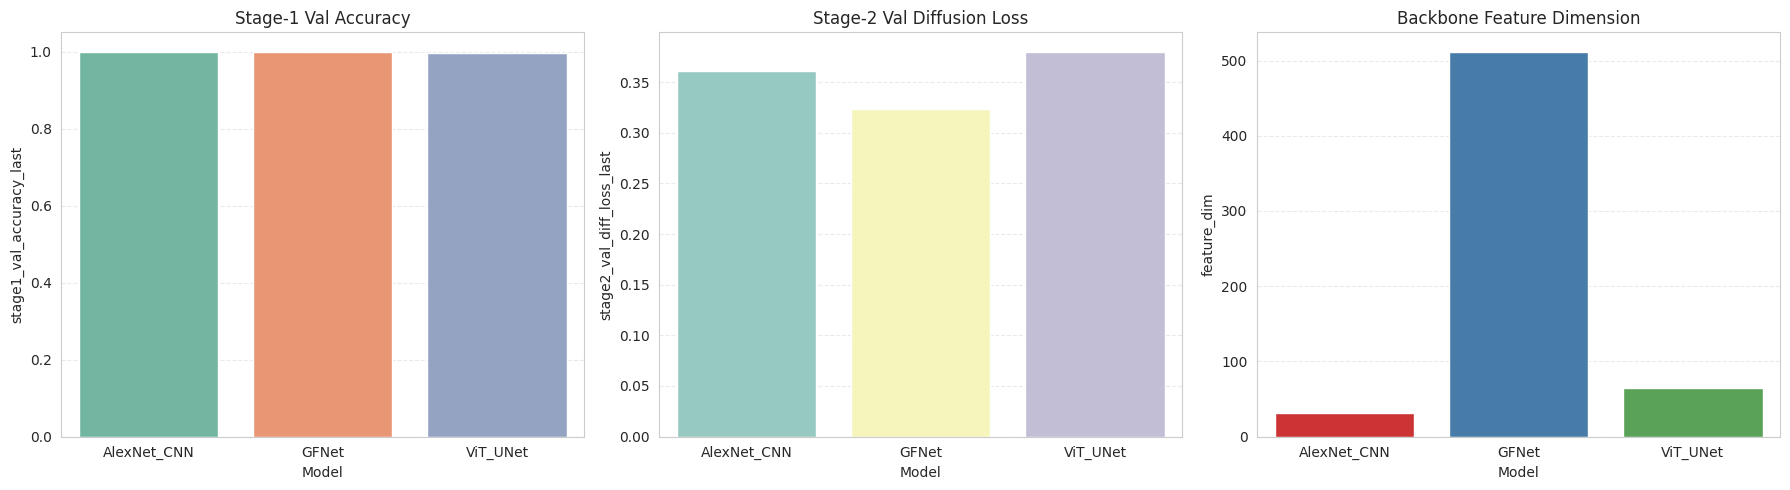

In [15]:
summary_df  = (
    pd.DataFrame([a['summary'] for a in all_artifacts])
    .sort_values('stage1_val_accuracy_last', ascending=False)
)
summary_csv = DAPM_DIR / 'dapm_full_training_summary.csv'
summary_df.to_csv(summary_csv, index=False)
print(summary_df)
print('Saved summary:', summary_csv)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=summary_df, x='model_key', y='stage1_val_accuracy_last', ax=axes[0], palette='Set2')
axes[0].set_title('Stage-1 Val Accuracy')
axes[0].set_ylim(0, 1.05)
sns.barplot(data=summary_df, x='model_key', y='stage2_val_diff_loss_last', ax=axes[1], palette='Set3')
axes[1].set_title('Stage-2 Val Diffusion Loss')
sns.barplot(data=summary_df, x='model_key', y='feature_dim', ax=axes[2], palette='Set1')
axes[2].set_title('Backbone Feature Dimension')
for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_xlabel('Model')
fig.tight_layout()
plt.show()


## 9.2 — File & Data Integrity Checks

Asserts that all expected weight files, config JSONs, and summary rows are present
before proceeding to evaluation.

In [16]:
EXPECTED_SUFFIXES = [
    '_dapm_full_config.json',
    '_dapm_full_encoder.weights.h5',
    '_dapm_full_source_decoder.weights.h5',
    '_dapm_full_target_decoder.weights.h5',
    '_dapm_full_classifier.weights.h5',
    '_dapm_full_discriminator.weights.h5',
    '_dapm_full_diffusion.weights.h5',
]

for mk in MODEL_KEYS:
    for suf in EXPECTED_SUFFIXES:
        path = DAPM_DIR / f'{mk}{suf}'
        assert path.exists(), f'Missing artifact: {path}'

assert summary_csv.exists(), f'Missing summary csv: {summary_csv}'
assert summary_df.shape[0] == 3, f'Expected 3 summary rows, got {summary_df.shape[0]}'

for mk, dim in feature_dims.items():
    assert np.isfinite(dim), f'Non-finite feature dim for {mk}'
    assert int(dim) > 0,     f'Invalid feature dim for {mk}: {dim}'

print('Validation checks passed.')


Validation checks passed.


# 10.0 — Evaluation on Test Set

## 10.1 — Inference Helper

Defines `predict_with_dapm_classifier`, which uses the encoder → classifier path
(no diffusion) to generate predictions on any patch array.

In [17]:
def predict_with_dapm_classifier(feature_extractor, encoder, classifier, x_data, batch_size=256):
    """Run encoder → classifier inference on x_data; returns (hard_preds, softmax_probs)."""
    ds        = tf.data.Dataset.from_tensor_slices(x_data.astype(np.float32)).batch(batch_size)
    all_probs = []
    for xb in ds:
        feat       = feature_extractor(xb, training=False)
        z_mu, _, _ = encoder(feat, training=False)
        probs      = classifier(z_mu, training=False)
        all_probs.append(probs.numpy())
    all_probs = np.concatenate(all_probs, axis=0)
    return np.argmax(all_probs, axis=-1), all_probs

print('Inference utility ready.')


Inference utility ready.


## 10.2 — Compute Metrics per Model

Reloads saved weights for each backbone, runs inference on the held-out test set,
and computes OA, AA, Cohen's Kappa, and weighted F1.

In [18]:
test_results = {}

for mk in MODEL_KEYS:
    print(f"\n{'='*20} {mk} {'='*20}")

    fe = feature_extractors[mk]
    with open(DAPM_DIR / f'{mk}_dapm_full_config.json', 'r') as f:
        cfg = json.load(f)

    # Rebuild lightweight architectures and load weights
    enc = build_dapm_encoder(cfg['feature_dim'], LATENT_DIM, DECODER_HIDDEN_DIM)
    clf = build_dapm_classifier(LATENT_DIM, num_classes, CLASSIFIER_HIDDEN_DIM)
    enc.load_weights(cfg['weights']['encoder'])
    clf.load_weights(cfg['weights']['classifier'])

    preds, probs = predict_with_dapm_classifier(fe, enc, clf, x_test)

    acc   = accuracy_score(y_test, preds)
    kappa = cohen_kappa_score(y_test, preds)
    wf1   = f1_score(y_test, preds, average='weighted')
    cm    = confusion_matrix(y_test, preds)
    cr    = classification_report(y_test, preds, digits=4)
    aa    = np.mean(cm.diagonal() / cm.sum(axis=1).clip(min=1))

    test_results[mk] = {
        'preds': preds, 'probs': probs,
        'cm': cm, 'cr': cr,
        'acc': acc, 'aa': aa, 'kappa': kappa, 'f1': wf1,
    }

    print(f'OA={acc:.4f}  AA={aa:.4f}  \u03ba={kappa:.4f}  wF1={wf1:.4f}')
    print(cr)



==================== AlexNet_CNN ====================
OA=0.9993  AA=0.9980  κ=0.9992  wF1=0.9993
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2432
           1     1.0000    1.0000    1.0000      1408
           2     1.0000    0.9982    0.9991       566
           3     0.9996    1.0000    0.9998      2729
           4     0.9991    1.0000    0.9995      3180
           5     0.9991    0.9991    0.9991      2119
           6     0.9950    0.9900    0.9925       399
           7     0.9984    0.9969    0.9977       641

    accuracy                         0.9993     13474
   macro avg     0.9989    0.9980    0.9985     13474
weighted avg     0.9993    0.9993    0.9993     13474

==================== GFNet ====================
OA=1.0000  AA=1.0000  κ=1.0000  wF1=1.0000
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      2432
           1     1.0000    1.0000    1.0000      14

# 11.0 — Visualisations

## 11.1 — Confusion Matrices (Raw Counts)


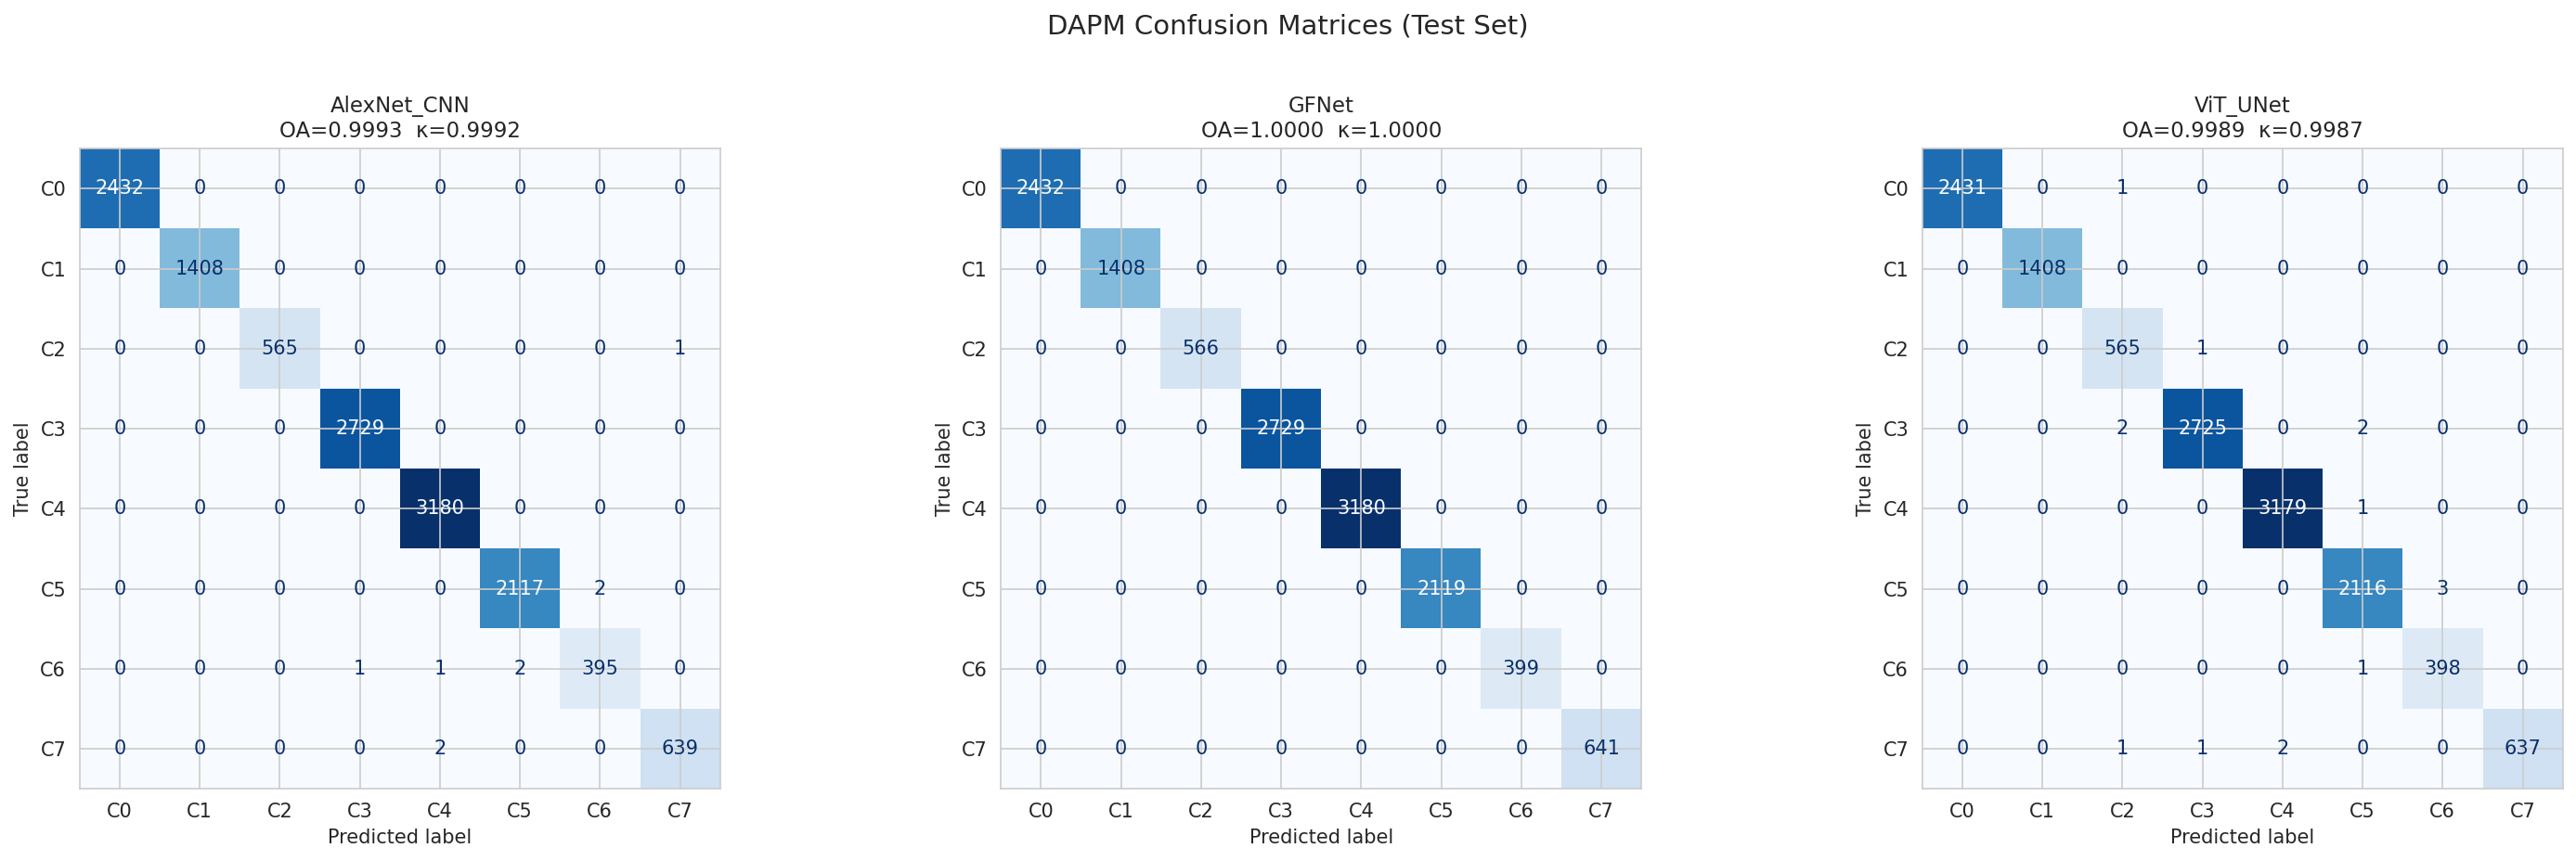

In [19]:
class_names = [f'C{i}' for i in range(num_classes)]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, mk in zip(axes, MODEL_KEYS):
    res = test_results[mk]
    ConfusionMatrixDisplay(
        confusion_matrix=res['cm'], display_labels=class_names
    ).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{mk}\nOA={res["acc"]:.4f}  \u03ba={res["kappa"]:.4f}', fontsize=11)

fig.suptitle('DAPM Confusion Matrices (Test Set)', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'confusion_matrices_raw.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.2 — Confusion Matrices (Normalised Recall)

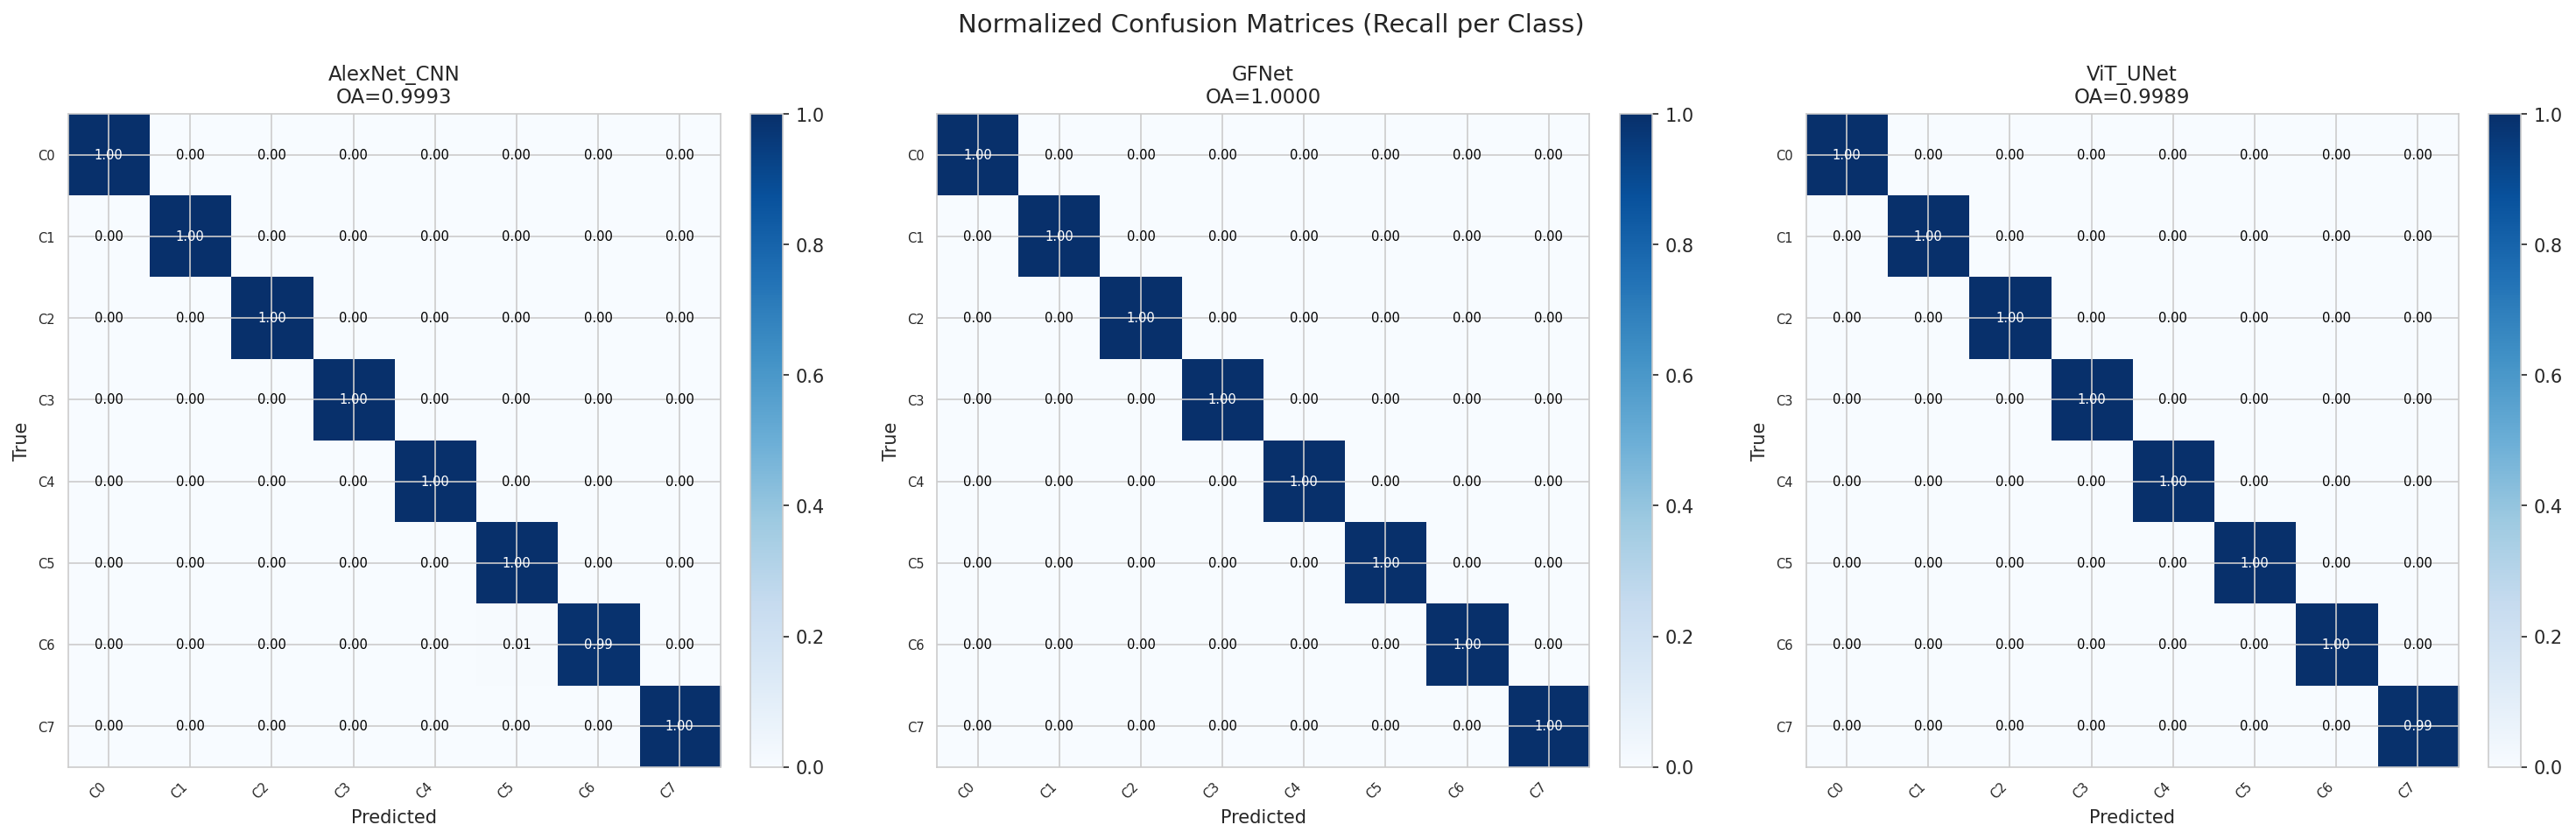

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, mk in zip(axes, MODEL_KEYS):
    cm      = test_results[mk]['cm']
    cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.set_xticks(range(num_classes))
    ax.set_yticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=7)
    ax.set_yticklabels(class_names, fontsize=7)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'{mk}\nOA={test_results[mk]["acc"]:.4f}', fontsize=11)

    for i in range(num_classes):
        for j in range(num_classes):
            ax.text(
                j, i, f'{cm_norm[i, j]:.2f}',
                ha='center', va='center', fontsize=7,
                color='white' if cm_norm[i, j] > 0.5 else 'black',
            )

    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle('Normalized Confusion Matrices (Recall per Class)', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'confusion_matrices_normalized.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.3 — Per-Class Accuracy (Recall) Bar Charts

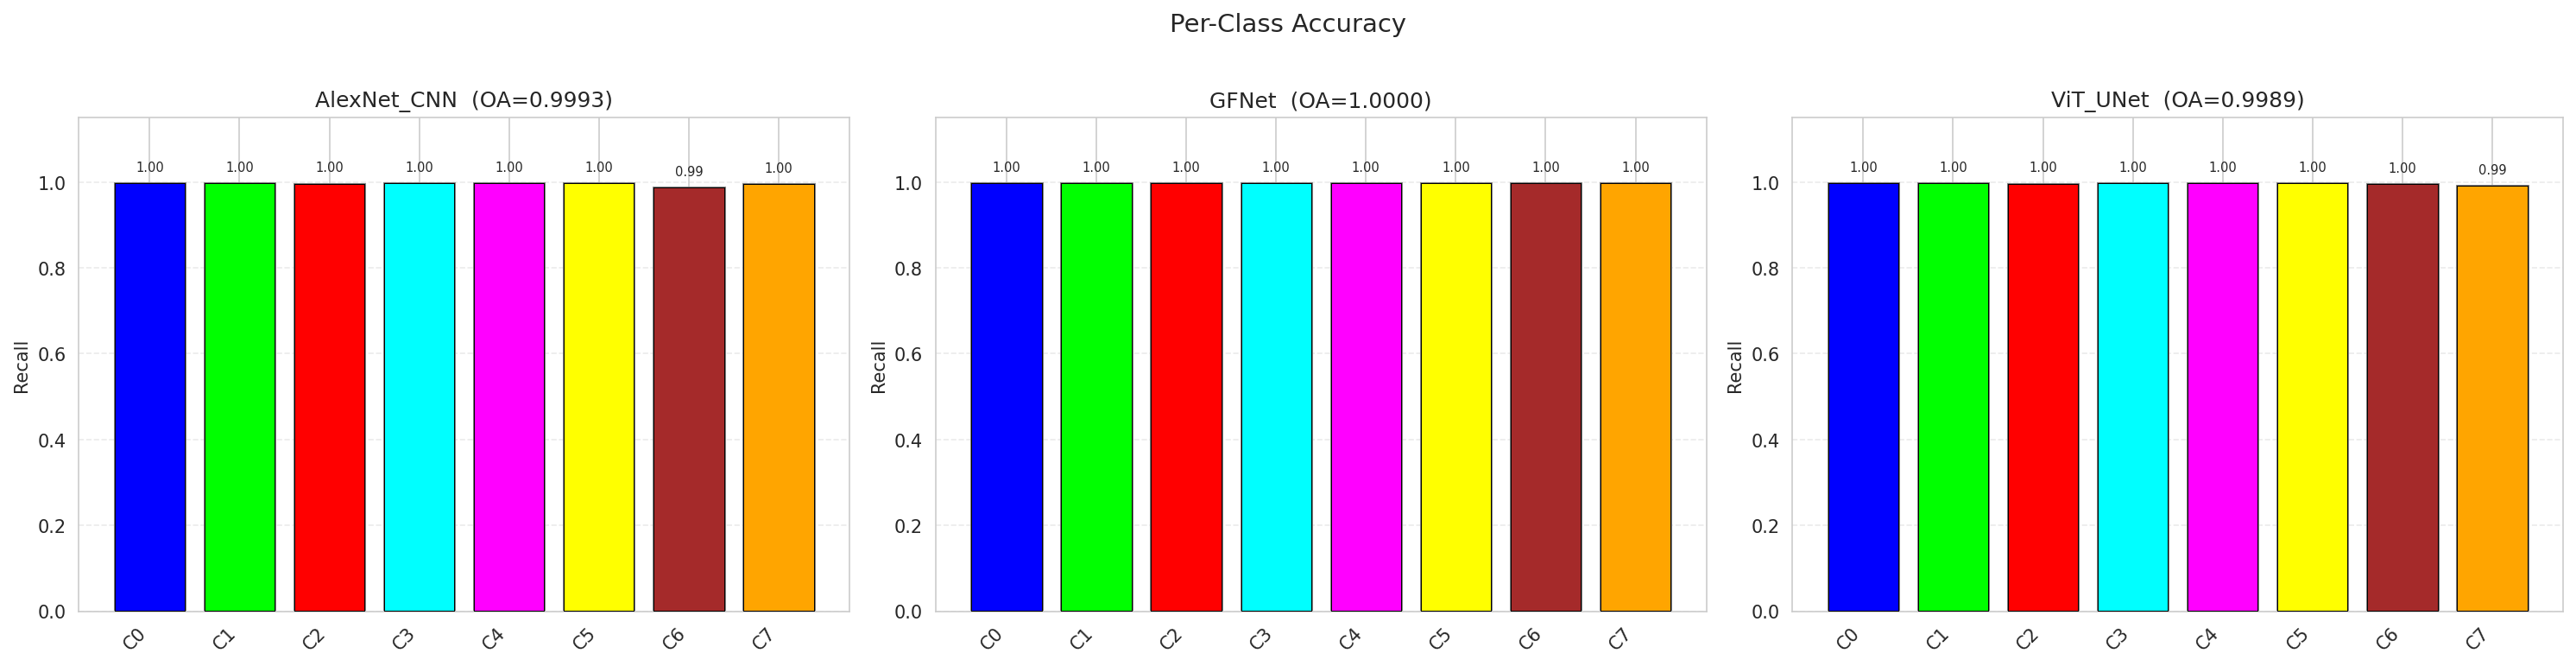

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, mk in zip(axes, MODEL_KEYS):
    cm        = test_results[mk]['cm']
    per_class = cm.diagonal() / cm.sum(axis=1).clip(min=1)
    colors    = get_class_colors(num_classes)

    bars = ax.bar(range(num_classes), per_class, color=colors, edgecolor='black', linewidth=0.8)
    for bar, v in zip(bars, per_class):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f'{v:.2f}',
                ha='center', va='bottom', fontsize=8, fontweight='bold')

    ax.set_xticks(range(num_classes))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_ylim(0, 1.15)
    ax.set_ylabel('Recall')
    ax.set_title(f'{mk}  (OA={test_results[mk]["acc"]:.4f})')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Per-Class Accuracy', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.4 — Global Metric Comparison (OA / AA / Kappa / wF1)

      Model       OA       AA    Kappa  Weighted-F1
AlexNet_CNN 0.999332 0.998018 0.999195     0.999331
      GFNet 1.000000 1.000000 1.000000     1.000000
   ViT_UNet 0.998887 0.998235 0.998659     0.998887


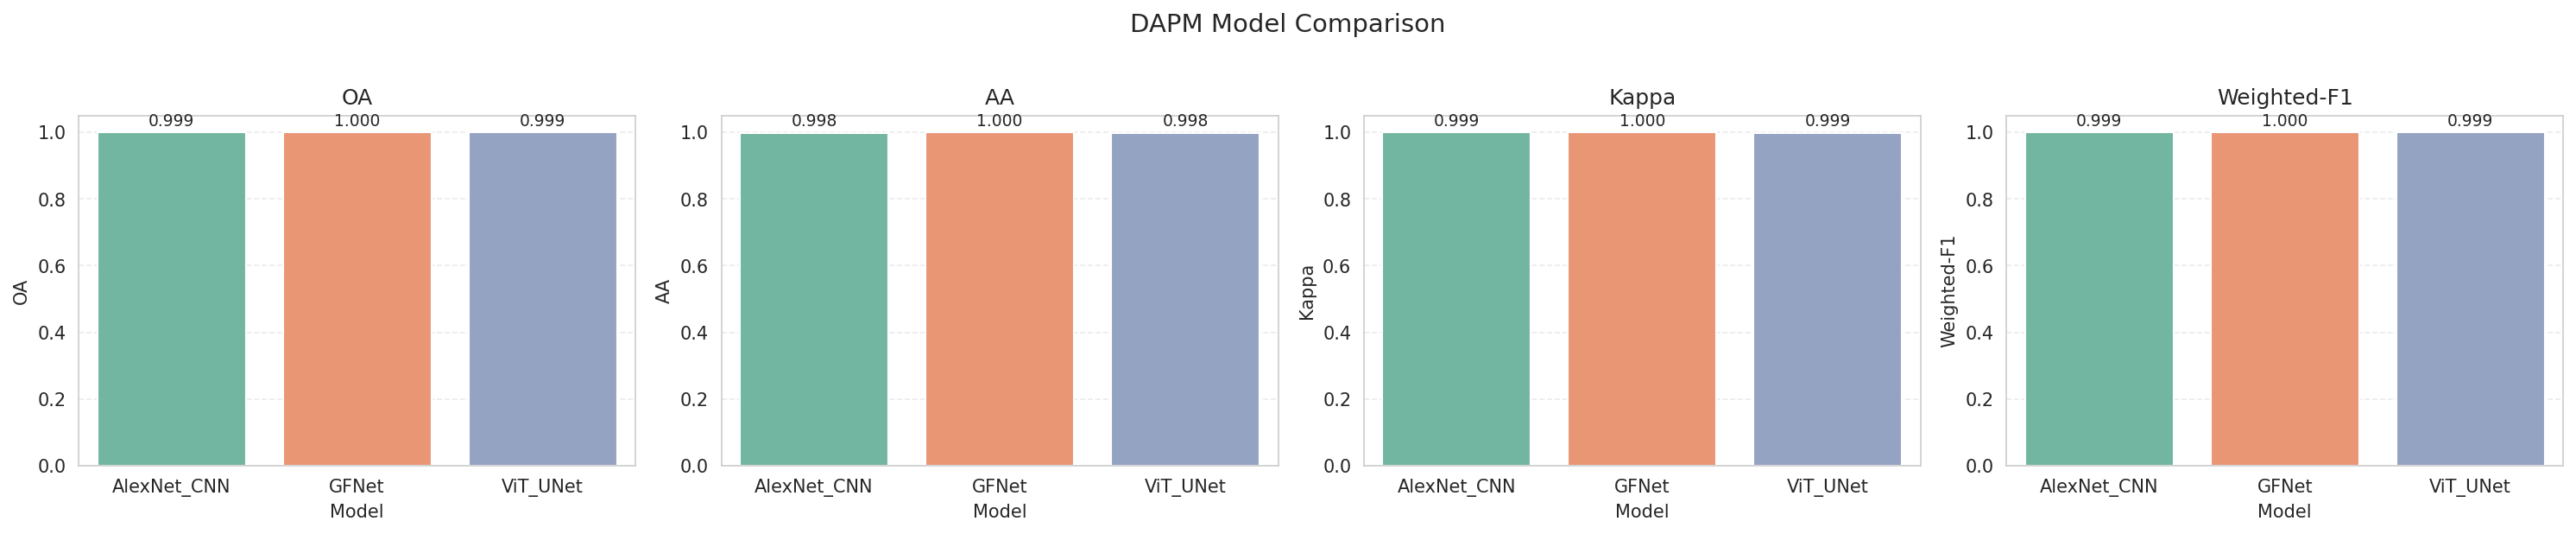

In [22]:
rows = [
    {'Model': mk, 'OA': r['acc'], 'AA': r['aa'], 'Kappa': r['kappa'], 'Weighted-F1': r['f1']}
    for mk, r in test_results.items()
]
comp_df = pd.DataFrame(rows)
print(comp_df.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, metric in zip(axes, ['OA', 'AA', 'Kappa', 'Weighted-F1']):
    sns.barplot(data=comp_df, x='Model', y=metric, ax=ax, palette='Set2')
    ax.set_ylim(0, 1.05)
    ax.set_title(metric)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.02,
                f'{p.get_height():.3f}', ha='center', fontsize=9)

fig.suptitle('DAPM Model Comparison', fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(DAPM_DIR / 'model_comparison_bars.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.5 — Full-Image Classification Maps

Applies each model to every pixel in the scene to produce a dense prediction map.
Processes row-by-row to keep memory usage manageable.

Predicting full image for AlexNet_CNN ...
  row 1/512
  row 51/512
  row 101/512
  row 151/512
  row 201/512
  row 251/512
  row 301/512
  row 351/512
  row 401/512
  row 451/512
  row 501/512
  row 512/512
  AlexNet_CNN done.
Predicting full image for GFNet ...
  row 1/512
  row 51/512
  row 101/512
  row 151/512
  row 201/512
  row 251/512
  row 301/512
  row 351/512
  row 401/512
  row 451/512
  row 501/512
  row 512/512
  GFNet done.
Predicting full image for ViT_UNet ...
  row 1/512
  row 51/512
  row 101/512
  row 151/512
  row 201/512
  row 251/512
  row 301/512
  row 351/512
  row 401/512
  row 451/512
  row 501/512
  row 512/512
  ViT_UNet done.
Saved: /kaggle/working/Classification/dapm/dapm_full_artifacts/scene_rgb.png
Saved: /kaggle/working/Classification/dapm/dapm_full_artifacts/ground_truth_label_map.png
Saved: /kaggle/working/Classification/dapm/dapm_full_artifacts/AlexNet_CNN_classification.png
Saved: /kaggle/working/Classification/dapm/dapm_full_artifacts/GFNet_classif

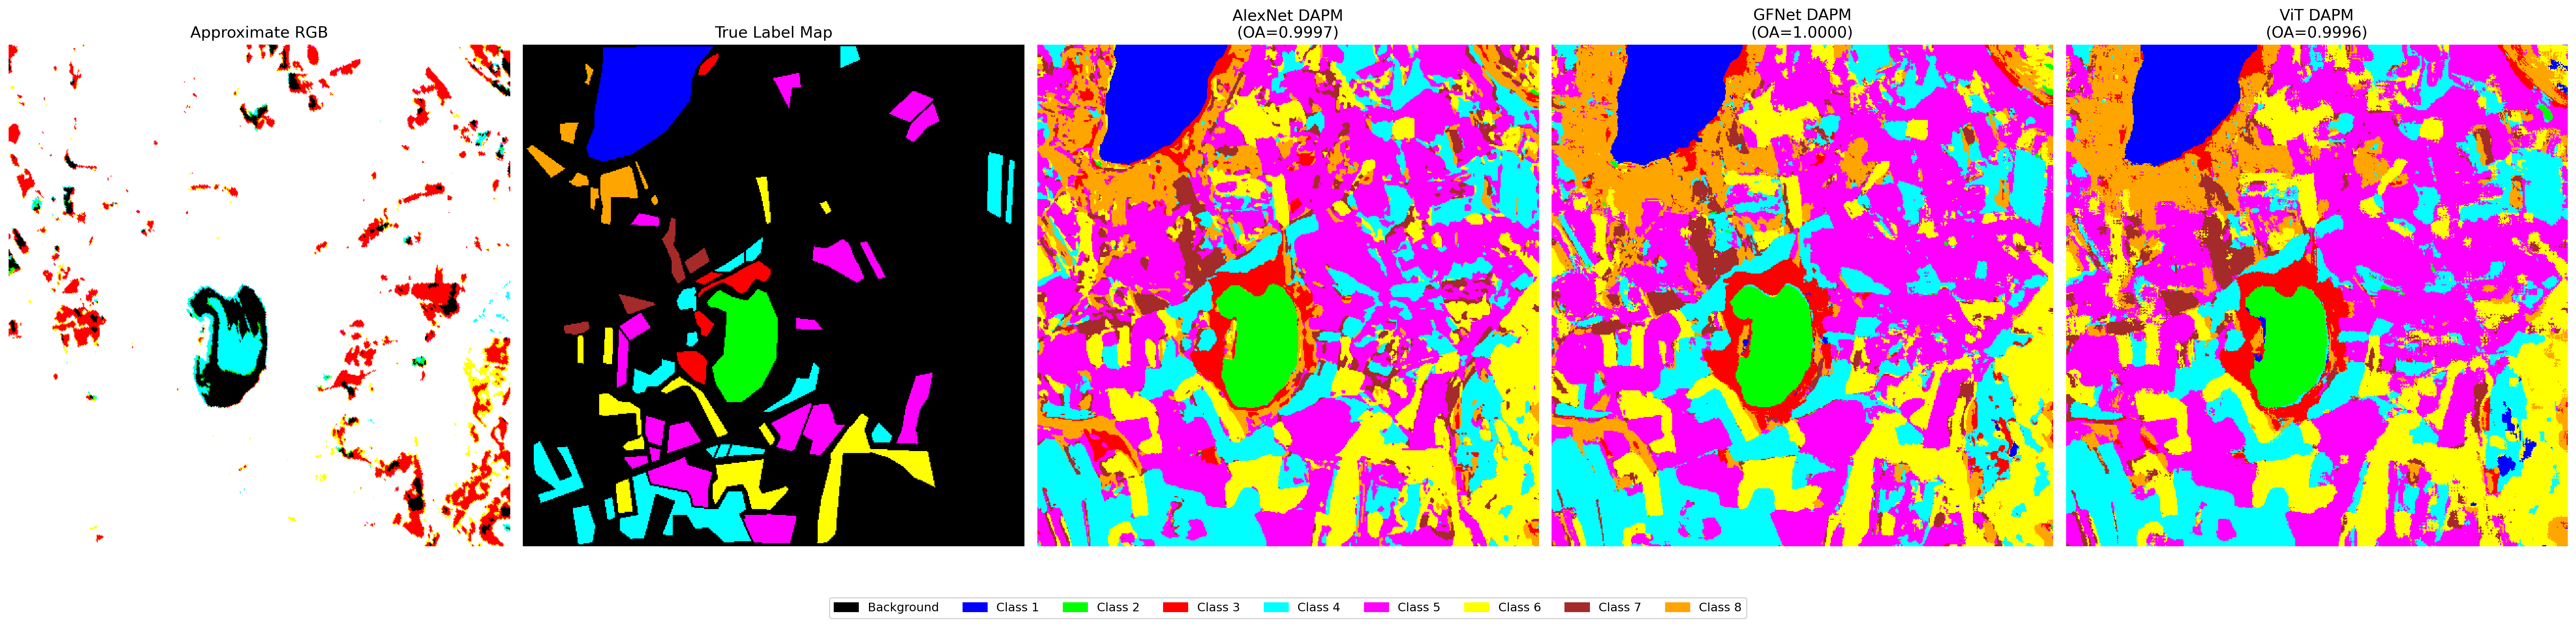

In [23]:
# ── Dense Full-Scene Inference & Classification Maps ──────────────────────────
display_cmap = get_display_cmap(num_classes)
scene_rgb    = get_scene_rgb(x_img, B)
full_maps    = {}

for mk in MODEL_KEYS:
    print(f'Predicting full image for {mk} ...')
    fe  = feature_extractors[mk]
    with open(DAPM_DIR / f'{mk}_dapm_full_config.json') as f:
        cfg = json.load(f)

    enc = build_dapm_encoder(cfg['feature_dim'], LATENT_DIM, DECODER_HIDDEN_DIM)
    clf = build_dapm_classifier(LATENT_DIM, num_classes, CLASSIFIER_HIDDEN_DIM)
    enc.load_weights(cfg['weights']['encoder'])
    clf.load_weights(cfg['weights']['classifier'])

    pad      = PATCH_SIZE // 2
    x_pad    = np.pad(x_img, ((pad, pad), (pad, pad), (0, 0)), mode='edge')
    pred_map = np.zeros((H, W), dtype=np.int32)

    for r in range(H):
        # Extract all W patches along row r in one batch
        patches = np.stack(
            [x_pad[r:r + PATCH_SIZE, c:c + PATCH_SIZE, :] for c in range(W)], axis=0
        )
        feat           = fe(patches, training=False)
        z_mu, _, _     = enc(feat, training=False)
        probs          = clf(z_mu, training=False)
        pred_map[r, :] = tf.argmax(probs, axis=-1).numpy() + 1  # 1-based (1..K)
        if r % 50 == 0 or r == H - 1:
            print(f'  row {r + 1}/{H}')

    full_maps[mk] = pred_map
    print(f'  {mk} done.')

# ── Visualization Helper Functions matching baseline ──────────────────────────
def save_single_panel(image, title, save_path, cmap=None, vmin=None, vmax=None):
    """Save a single image panel as a high-DPI PNG."""
    fig, ax = plt.subplots(figsize=(8, 6))
    if cmap is None:
        ax.imshow(image)
    else:
        ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_title(title, fontsize=14)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(save_path, dpi=220, bbox_inches='tight')
    plt.close(fig)
    print('Saved:', save_path)

def save_combined_overview(rgb_image, y_true, pred_maps, test_res, num_classes, save_path):
    """Save a clean five-panel side-by-side overview with non-overlapping horizontal legend."""
    cmap = get_display_cmap(num_classes)
    panels = [
        ("Approximate RGB",                rgb_image,                  "rgb"),
        ("True Label Map",                 y_true,                     "label"),
        (f"AlexNet DAPM\n(OA={test_res['AlexNet_CNN']['acc']:.4f})", pred_maps.get("AlexNet_CNN"), "label"),
        (f"GFNet DAPM\n(OA={test_res['GFNet']['acc']:.4f})",       pred_maps.get("GFNet"),       "label"),
        (f"ViT DAPM\n(OA={test_res['ViT_UNet']['acc']:.4f})",     pred_maps.get("ViT_UNet"),    "label"),
    ]

    fig, axes = plt.subplots(1, len(panels), figsize=(30, 7), sharex=True, sharey=True)
    for ax, (title, img, kind) in zip(axes, panels):
        ax.set_title(title, fontsize=13)
        if kind == "rgb":
            ax.imshow(img)
        elif img is None:
            ax.imshow(np.zeros_like(y_true), cmap=cmap, vmin=0, vmax=num_classes, interpolation='nearest')
            ax.text(0.5, 0.5, "Unavailable", ha="center", va="center", fontsize=10, transform=ax.transAxes)
        else:
            ax.imshow(img, cmap=cmap, vmin=0, vmax=num_classes, interpolation='nearest')
        ax.axis("off")

    handles = [plt.Rectangle((0, 0), 1, 1, color=BACKGROUND_COLOR, label="Background")]
    class_colors = get_class_colors(num_classes)
    for i in range(num_classes):
        handles.append(plt.Rectangle((0, 0), 1, 1, color=class_colors[i], label=f"Class {i+1}"))
    fig.legend(handles=handles, loc="lower center", ncol=min(num_classes + 1, 9),
               bbox_to_anchor=(0.5, -0.02), frameon=True)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    fig.savefig(save_path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved overview:', save_path)

def save_images_to_excel(excel_path, image_paths, sheet_name="Initial_Classification_Maps"):
    """Embed PNG images into an Excel workbook at fixed anchor positions."""
    try:
        from openpyxl import Workbook, load_workbook
        from openpyxl.drawing.image import Image as XLImage
    except ImportError:
        print("openpyxl not available; skipping Excel image embedding.")
        return

    if excel_path.exists():
        wb = load_workbook(excel_path)
        if sheet_name in wb.sheetnames:
            del wb[sheet_name]
        ws = wb.create_sheet(title=sheet_name)
    else:
        wb = Workbook()
        ws = wb.active
        ws.title = sheet_name

    anchors = ["A1", "J1", "A25", "J25", "A49", "J49"]
    for path, anchor in zip(image_paths, anchors):
        if Path(path).exists():
            img = XLImage(str(path))
            img.anchor = anchor
            ws.add_image(img)

    wb.save(excel_path)
    print("Saved Excel workbook:", excel_path)

# ── Save Individual PNGs and Combined Overview ─────────────────────────────────
rgb_png      = DAPM_DIR / "scene_rgb.png"
gt_png       = DAPM_DIR / "ground_truth_label_map.png"
alex_png     = DAPM_DIR / "AlexNet_CNN_classification.png"
gfnet_png    = DAPM_DIR / "GFNet_classification.png"
vit_png      = DAPM_DIR / "ViT_UNet_classification.png"
overview_png = DAPM_DIR / "full_image_classification_maps.png"
combined_png = DAPM_DIR / "combined_initial_classification_overview.png"
vis_excel    = DAPM_DIR / "initial_classification_maps.xlsx"

save_single_panel(scene_rgb, "Approximate RGB", rgb_png)
save_single_panel(y_img, "Ground Truth Label Map", gt_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("AlexNet_CNN") is not None:
    save_single_panel(full_maps["AlexNet_CNN"], "AlexNet DAPM Classification",
                      alex_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("GFNet") is not None:
    save_single_panel(full_maps["GFNet"], "GFNet DAPM Classification",
                      gfnet_png, cmap=display_cmap, vmin=0, vmax=num_classes)

if full_maps.get("ViT_UNet") is not None:
    save_single_panel(full_maps["ViT_UNet"], "ViT DAPM Classification",
                      vit_png, cmap=display_cmap, vmin=0, vmax=num_classes)

save_combined_overview(
    rgb_image=scene_rgb, y_true=y_img, pred_maps=full_maps,
    test_res=test_results, num_classes=num_classes, save_path=overview_png,
)
# Save copy to combined_initial_classification_overview.png for baseline symmetry
import shutil
shutil.copy2(overview_png, combined_png)

# Save into Excel
image_paths_for_excel = [rgb_png, gt_png, alex_png, gfnet_png, vit_png, overview_png]
save_images_to_excel(vis_excel, image_paths_for_excel)

print("All visualisation outputs successfully saved to:", DAPM_DIR)
